In [1]:
# Install Kaggle CLI
!pip install -q kaggle

# Upload your Kaggle API key
from google.colab import files
files.upload()  # Upload kaggle.json

# Setup credentials
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download dataset
!kaggle datasets download -d pratik2901/multiclass-weather-dataset

# Unzip dataset
!unzip -q multiclass-weather-dataset.zip -d /content/multi_weather_data

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/pratik2901/multiclass-weather-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
  0% 0.00/91.4M [00:00<?, ?B/s]
100% 91.4M/91.4M [00:00<00:00, 1.87GB/s]


In [2]:
# Core Python Libraries
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# TensorFlow / Keras Libraries
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical

# Optional: To suppress TensorFlow warnings (for cleaner logs)
import warnings
warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')

Found 901 images belonging to 4 classes.
Found 224 images belonging to 4 classes.


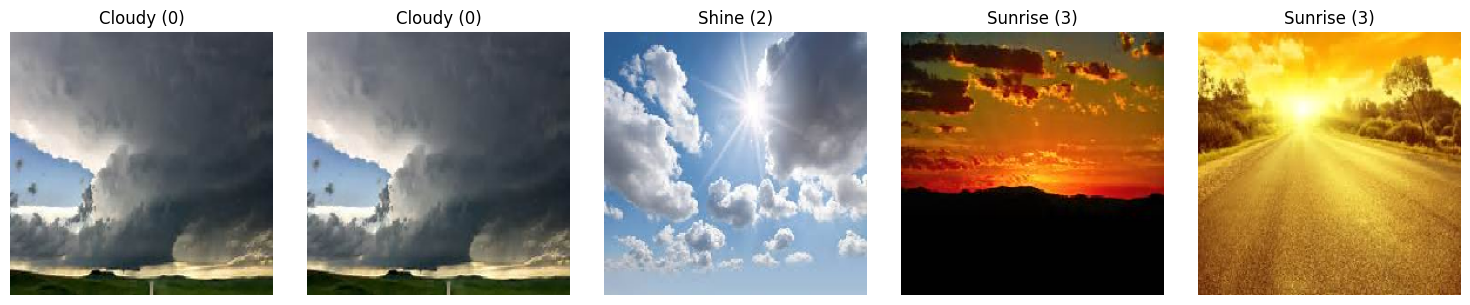

In [8]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
import random

# Path to your dataset root directory
data_dir = "/content/multi_weather_data/Multi-class Weather Dataset"

# Define class names (should match folder names)
class_names = ["Cloudy", "Rain", "Shine", "Sunrise"]

# Image Data Generator for preprocessing and augmentation
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2  # 80% train, 20% validation
)

# Train generator
train_loader = datagen.flow_from_directory(
    data_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

# Validation/Test generator
test_loader = datagen.flow_from_directory(
    data_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# ✅ Function to show random samples
def show_random_samples(data_gen, class_names, num_samples=5):
    images, labels = next(data_gen)
    plt.figure(figsize=(15, 3))

    for i in range(num_samples):
        idx = random.randint(0, len(images) - 1)
        img = images[idx]
        label = np.argmax(labels[idx])

        plt.subplot(1, num_samples, i + 1)
        plt.imshow(img)
        plt.title(f"{class_names[label]} ({label})")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

# ✅ Show random images from training data
show_random_samples(train_loader, class_names, num_samples=5)


In [9]:
from tensorflow.keras import layers, models

def build_weather_cnn(input_shape=(224, 224, 3), num_classes=4):
    model = models.Sequential([
        # Conv Block 1
        layers.Conv2D(32, (2, 2), padding='same', activation='relu', input_shape=input_shape),
        layers.MaxPooling2D(pool_size=(2, 2), padding='same'),

        # Conv Block 2
        layers.Conv2D(64, (2, 2), padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2), padding='same'),

        # Conv Block 3
        layers.Conv2D(128, (2, 2), padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2), padding='same'),

        # Conv Block 4
        layers.Conv2D(256, (2, 2), padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2), padding='same'),

        # Flatten + Dense Layers
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.3),

        # Output Layer
        layers.Dense(num_classes, activation='sigmoid')
    ])

    # Compile the model
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# ✅ Create and summarize model
model = build_weather_cnn()
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    12,845,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,019,236 (49.66 MB)

 Trainable params: 13,019,236 (49.66 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Build your CNN model
model = build_weather_cnn()

# Display model summary
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │    12,845,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,019,236 (49.66 MB)

 Trainable params: 13,019,236 (49.66 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# ✅ Device automatically handled by TensorFlow (no need for manual cuda/device setup)
import tensorflow as tf

# Build and compile your CNN model
model = build_weather_cnn()

# Define loss function, optimizer, and metrics (similar to PyTorch)
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

model.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=['accuracy']
)

In [15]:
import tensorflow as tf

# Define your dataset directory
data_dir = "/content/multi_weather_data/Multi-class Weather Dataset"

# Split dataset into 80% train and 20% test
train_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(224, 224),
    batch_size=32
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(224, 224),
    batch_size=32
)

Found 1125 files belonging to 4 classes.
Using 900 files for training.
Found 1125 files belonging to 4 classes.
Using 225 files for validation.


In [16]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)


In [17]:
normalization_layer = tf.keras.layers.Rescaling(1./255)
train_dataset = train_dataset.map(lambda x, y: (normalization_layer(x), y))
test_dataset = test_dataset.map(lambda x, y: (normalization_layer(x), y))


In [18]:
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=10
)

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.5116 - loss: 1.1275 - val_accuracy: 0.6933 - val_loss: 0.6184
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.7921 - loss: 0.5433 - val_accuracy: 0.8889 - val_loss: 0.3820
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.8932 - loss: 0.3292 - val_accuracy: 0.9022 - val_loss: 0.2793
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.8918 - loss: 0.2449 - val_accuracy: 0.8533 - val_loss: 0.4025
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.9041 - loss: 0.2408 - val_accuracy: 0.8667 - val_loss: 0.3653
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.9360 - loss: 0.1819 - val_accuracy: 0.9067 - val_loss: 0.3128
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - accuracy: 0.9386 - loss: 0.1645 - val_accuracy: 0.8444 - val_loss: 0.5146
Epoch 8/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.9463 - loss: 0.1322 - val_accuracy: 0.9067 - val_loss:

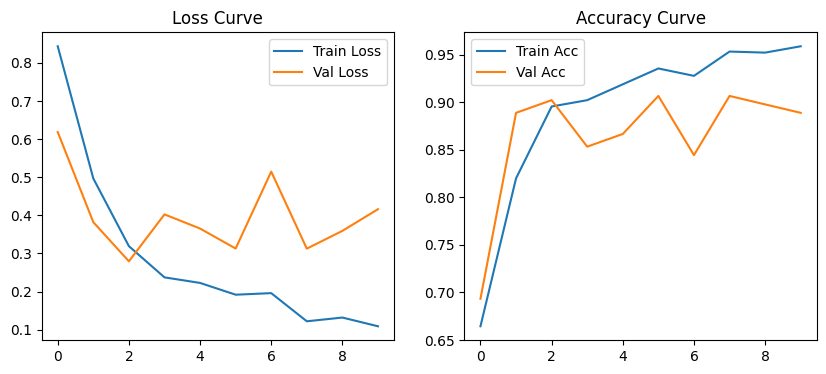

In [19]:
# Plot training loss and accuracy
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("Loss Curve")

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.legend()
plt.title("Accuracy Curve")
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 588ms/step


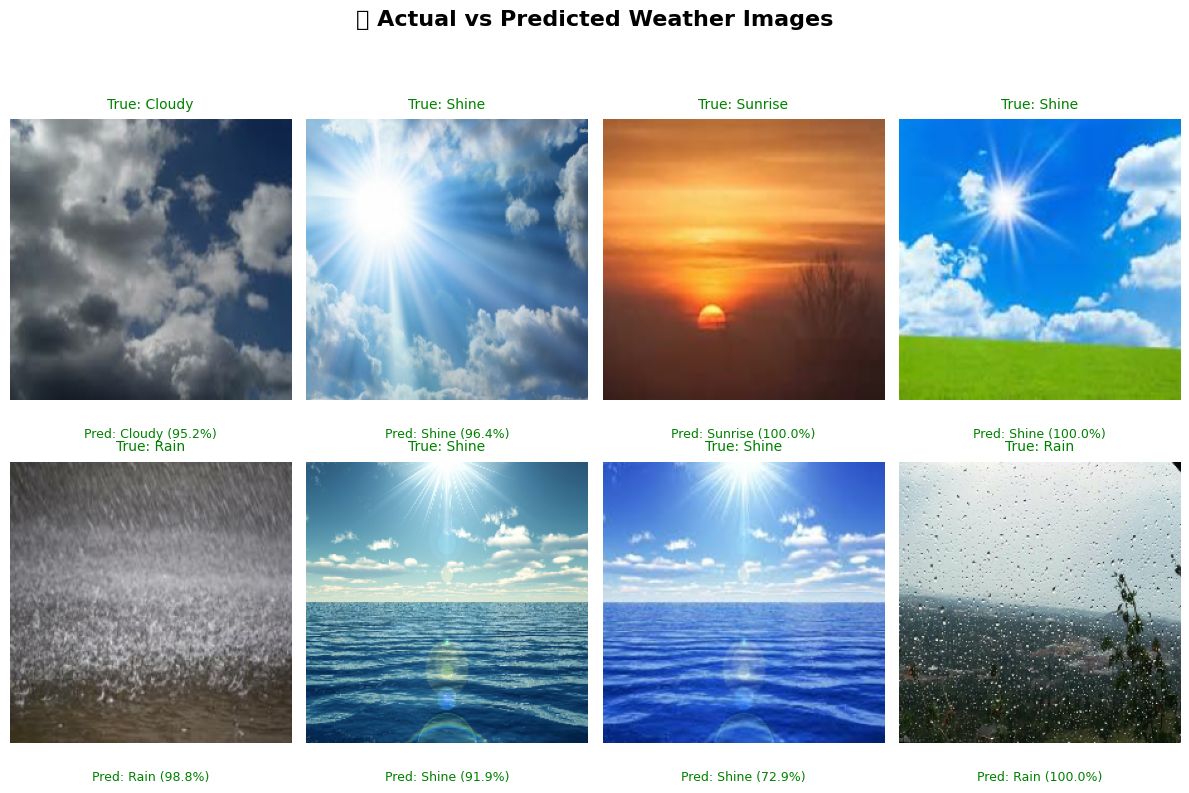

In [32]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# ✅ Define your class names (same order as in your dataset)
class_names = ["Cloudy", "Rain", "Shine", "Sunrise"]

# ✅ Get one batch from the test dataset
test_images, test_labels = next(iter(test_dataset.take(1)))

# ✅ Predict on the batch
pred_probs = model.predict(test_images)
pred_classes = np.argmax(pred_probs, axis=1)

# ✅ Handle both integer and one-hot encoded labels
if len(test_labels.shape) > 1 and test_labels.shape[1] > 1:
    true_classes = np.argmax(test_labels, axis=1)
else:
    true_classes = test_labels.numpy()

# ✅ Plot Actual (top) and Predicted (bottom)
plt.figure(figsize=(12, 8))
plt.suptitle("🌤️ Actual vs Predicted Weather Images", fontsize=16, fontweight='bold')

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(test_images[i])
    plt.axis('off')

    true_label = class_names[int(true_classes[i])]
    pred_label = class_names[int(pred_classes[i])]
    pred_conf = np.max(pred_probs[i]) * 100

    color = "green" if pred_label == true_label else "red"

    # 🟢 Actual label (TOP)
    plt.title(f"True: {true_label}", fontsize=10, color='green', pad=8)

    # 🔴 Predicted label (BOTTOM)
    plt.text(
        0.5, -0.12,
        f"Pred: {pred_label} ({pred_conf:.1f}%)",
        ha='center',
        va='center',
        transform=plt.gca().transAxes,
        fontsize=9,
        color=color
    )

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### Save Model in H5 Format

This will save the model's architecture, weights, and optimizer state to a single HDF5 (`.h5`) file. This is a common and recommended way to save TensorFlow/Keras models.

In [33]:
model.save('weather_cnn_model.h5')
print("Model saved as weather_cnn_model.h5")

Model saved as weather_cnn_model.h5


### Save Model in Native Keras Format

Introduced in TensorFlow 2.x, the native Keras format (`.keras` extension) is a more robust and recommended way to save models, as it can handle custom objects better than H5.

In [34]:
model.save('weather_cnn_model.keras')
print("Model saved as weather_cnn_model.keras")

Model saved as weather_cnn_model.keras


### Save Model using Pickle Format

While technically possible to pickle a Keras model, it is generally **not recommended** due to potential compatibility issues across different TensorFlow/Keras versions and complexities with custom layers or functions. The `.h5` and `.keras` formats are preferred. However, if you specifically need it, here's how you can save it using `pickle`.

In [35]:
import pickle

with open('weather_cnn_model.pkl', 'wb') as f:
    pickle.dump(model, f)
print("Model saved as weather_cnn_model.pkl")

Model saved as weather_cnn_model.pkl
